# 03 · Exploratory Data Analysis (EDA)
**Education Insights Lab: Diagnosing Educational Opportunity and Outcomes**

**Purpose.** Understand the shape of the K-12 data and build intuition about the question *before* any formal testing or modelling. EDA here is not "make charts"; every plot answers a specific question and ends with a stated reading.

**Scope.** The K-12 analysis file produced in notebook 02 (4,642 schools).

**Contents**
1. Setup
2. Univariate analysis: what does each variable look like?
3. Bivariate analysis: which variables move together?
4. Multivariate analysis: do relationships survive once poverty is considered?
5. EDA takeaways and what they imply for the statistics and modelling

## 1. Setup

In [1]:
import sys, warnings
sys.path.append('../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from utils import PATHS, set_style, save_fig, PALETTE
from data_cleaning import load_k12
set_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

k12 = load_k12()
print(f'{len(k12):,} K-12 schools | {k12.shape[1]} columns')
k12[['level', 'control', 'locale_group', 'title_i_status', 'poverty_tertile']].describe().T

4,642 K-12 schools | 48 columns


,count,unique,top,freq
level,4642,4,Elementary School,2225
control,4642,5,Public,3315
locale_group,4642,4,Suburban,1989
title_i_status,4642,4,Title I Schoolwide,2180
poverty_tertile,4642,3,Mid poverty,1550


## 2. Univariate analysis

**Question:** what does each key variable look like on its own (centre, spread, shape, unusual values)?

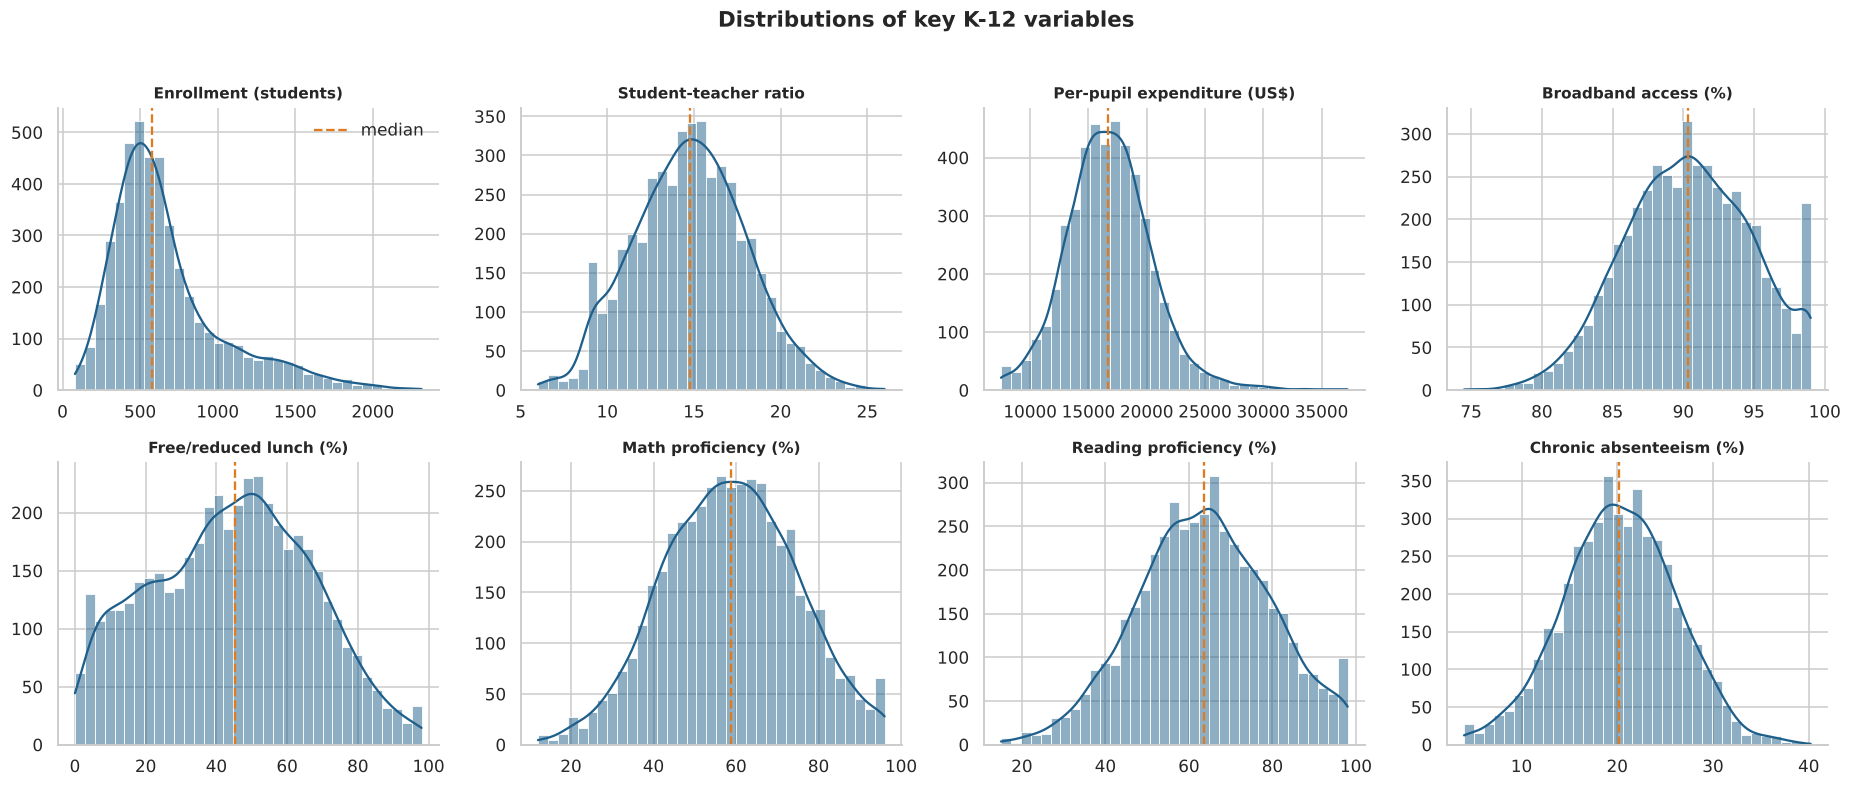

In [2]:
uni_vars = {
    'total_enrollment': 'Enrollment (students)',
    'student_teacher_ratio': 'Student-teacher ratio',
    'per_pupil_expenditure_usd': 'Per-pupil expenditure (US$)',
    'broadband_access_pct': 'Broadband access (%)',
    'percent_free_reduced_lunch': 'Free/reduced lunch (%)',
    'math_proficiency_pct': 'Math proficiency (%)',
    'reading_proficiency_pct': 'Reading proficiency (%)',
    'chronic_absenteeism_pct': 'Chronic absenteeism (%)',
}

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (col, label) in zip(axes.ravel(), uni_vars.items()):
    sns.histplot(k12[col], bins=35, kde=True, ax=ax, color=PALETTE['primary'])
    ax.axvline(k12[col].median(), color=PALETTE['accent'], ls='--', lw=1.5, label='median')
    ax.set_title(label, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
axes[0, 0].legend(frameon=False)
plt.suptitle('Distributions of key K-12 variables', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout(); save_fig('03_univariate_distributions'); plt.show()

In [3]:
desc = k12[list(uni_vars)].describe().T
desc['skew'] = k12[list(uni_vars)].skew()
desc['kurtosis'] = k12[list(uni_vars)].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
total_enrollment,4642.0,672.23,370.84,80.0,425.25,576.0,804.00,2314.0,1.40,1.95
student_teacher_ratio,4642.0,14.79,3.24,6.0,12.50,14.8,17.00,26.0,0.10,-0.16
per_pupil_expenditure_usd,4642.0,16814.07,3685.31,7500.0,14434.50,16711.0,18945.75,37235.0,0.55,1.70
broadband_access_pct,4642.0,90.39,4.46,74.5,87.30,90.3,93.70,99.0,-0.09,-0.42
percent_free_reduced_lunch,4642.0,44.18,22.46,0.0,26.70,45.2,60.90,98.0,0.02,-0.72
math_proficiency_pct,4642.0,58.66,16.05,12.0,47.10,58.7,70.00,96.0,-0.03,-0.32
reading_proficiency_pct,4642.0,63.55,15.91,15.0,52.80,63.6,74.70,98.0,-0.06,-0.29
chronic_absenteeism_pct,4642.0,20.23,5.87,4.0,16.30,20.2,24.20,40.2,-0.02,-0.04


**Reading the distributions.**
- **Enrollment** is right-skewed (most schools are small, a few are big), which is why I will use `log(enrollment)` in models.
- **Math and reading proficiency, student-teacher ratio, and absenteeism** are close to symmetric, which suits linear modelling and means no transformation of the target is needed.
- **Per-pupil expenditure** has a mild right tail.
- **Broadband access** is roughly symmetric and tightly clustered: most schools sit in the high 80s to mid 90s (median about 90%). The variation is narrow, so a few percentage points of difference between schools is meaningful.

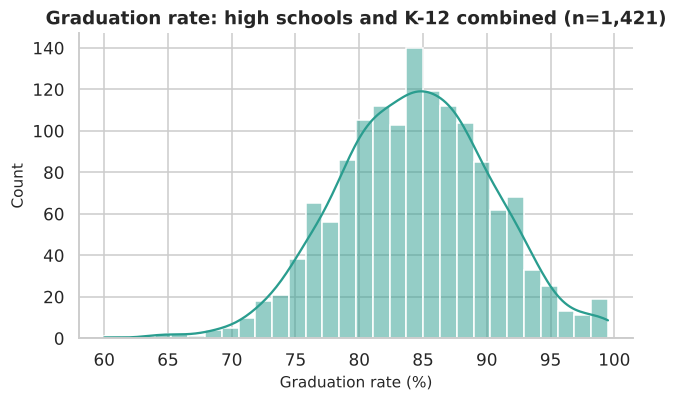

count    1421.0
mean       84.4
std         6.0
min        60.0
25%        80.3
50%        84.4
75%        88.4
max        99.5


In [4]:
# Graduation rate only makes sense for schools that graduate students.
grad = k12.loc[k12['level'].isin(['High School', 'K-12 Combined']), 'graduation_rate_pct']
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.histplot(grad, bins=30, kde=True, color=PALETTE['good'], ax=ax)
ax.set_title(f'Graduation rate: high schools and K-12 combined (n={grad.notna().sum():,})')
ax.set_xlabel('Graduation rate (%)')
save_fig('03_graduation_rate'); plt.show()
print(grad.describe().round(1).to_string())

### Categorical variables

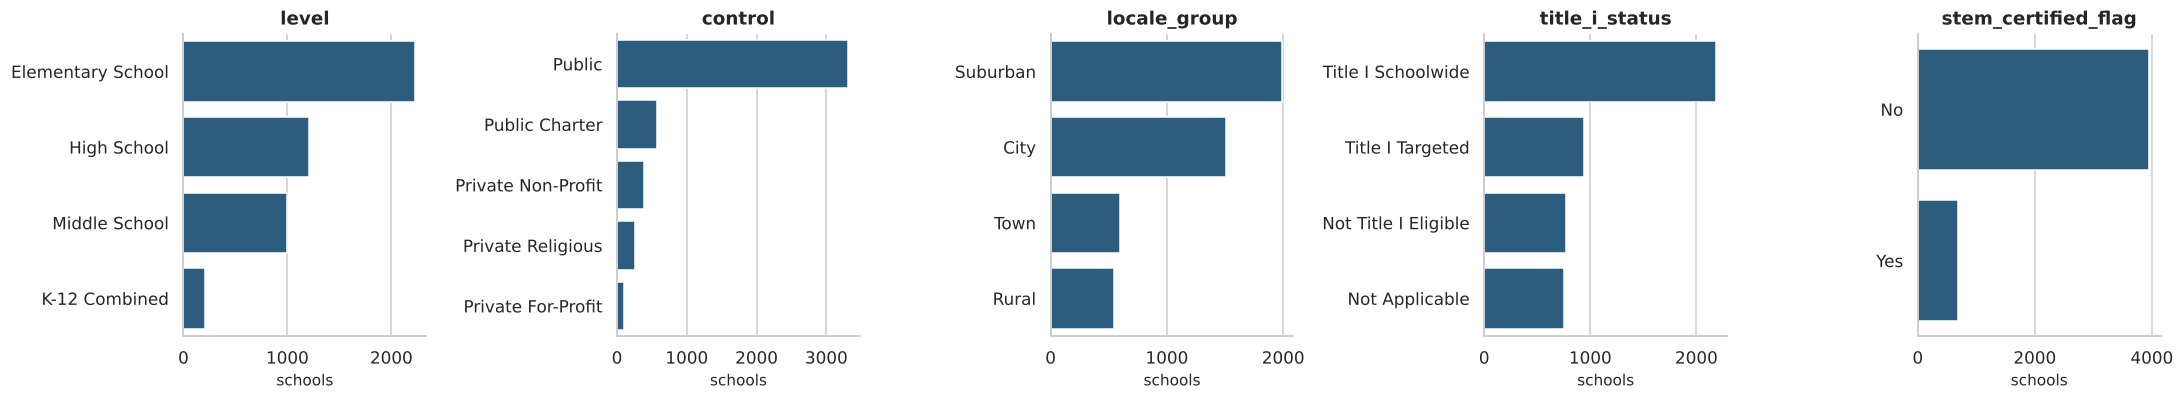

STEM-certified share: 14.8%


In [5]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, col in zip(axes, ['level', 'control', 'locale_group', 'title_i_status', 'stem_certified_flag']):
    order = k12[col].value_counts().index
    sns.countplot(data=k12, y=col, order=order, ax=ax, color=PALETTE['primary'])
    ax.set_title(col); ax.set_ylabel(''); ax.set_xlabel('schools')
plt.tight_layout(); save_fig('03_categorical_counts'); plt.show()

print('STEM-certified share:', f"{k12['stem_certified'].mean():.1%}")

**Reading the categories.** Elementary schools are the biggest group, most schools are public, and suburban/city locales dominate. Title I *Schoolwide* is the single largest Title I category. Only a minority of schools are STEM certified, so STEM status is an **imbalanced** binary variable (relevant if I ever model it, which I am not doing as the primary task).

## 3. Bivariate analysis

**Question:** which variables are associated with math proficiency, and how strongly?

### 3.1 Numeric predictors versus math proficiency
Each panel shows the raw points, a LOWESS (locally weighted) curve to reveal the *shape* of the relationship without forcing a straight line, and both Pearson (linear) and Spearman (rank) correlations.

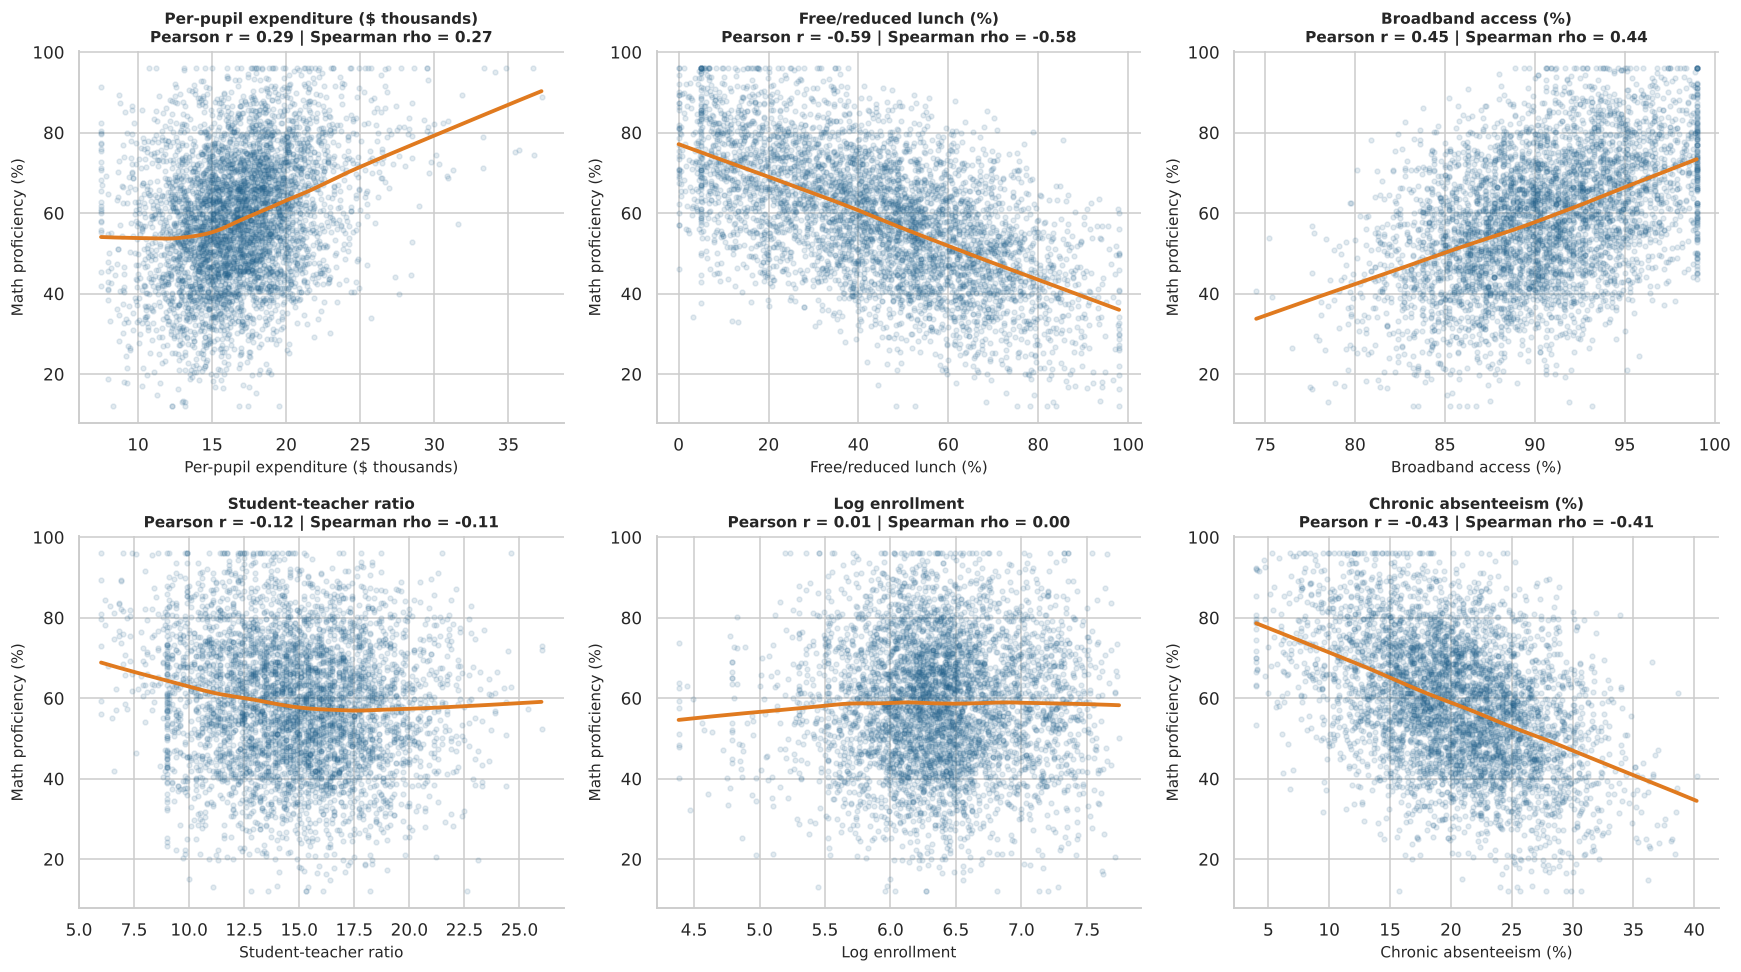

In [6]:
pairs = {
    'ppe_k': 'Per-pupil expenditure ($ thousands)',
    'percent_free_reduced_lunch': 'Free/reduced lunch (%)',
    'broadband_access_pct': 'Broadband access (%)',
    'student_teacher_ratio': 'Student-teacher ratio',
    'log_enrollment': 'Log enrollment',
    'chronic_absenteeism_pct': 'Chronic absenteeism (%)',
}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (col, label) in zip(axes.ravel(), pairs.items()):
    sns.regplot(data=k12, x=col, y='math_proficiency_pct', lowess=True, ax=ax,
                scatter_kws={'alpha': 0.12, 's': 10, 'color': PALETTE['primary']},
                line_kws={'color': PALETTE['accent'], 'lw': 2.5})
    r = k12[col].corr(k12['math_proficiency_pct'])
    rho = stats.spearmanr(k12[col], k12['math_proficiency_pct'])[0]
    ax.set_title(f'{label}\nPearson r = {r:.2f} | Spearman rho = {rho:.2f}', fontsize=10)
    ax.set_xlabel(label); ax.set_ylabel('Math proficiency (%)')
plt.tight_layout(); save_fig('03_bivariate_scatter'); plt.show()

In [7]:
bivar = pd.DataFrame({
    'pearson_r': {c: k12[c].corr(k12['math_proficiency_pct']) for c in pairs},
    'spearman_rho': {c: stats.spearmanr(k12[c], k12['math_proficiency_pct'])[0] for c in pairs},
}).round(3)
bivar['abs_r'] = bivar['pearson_r'].abs()
bivar.sort_values('abs_r', ascending=False).drop(columns='abs_r')

,pearson_r,spearman_rho
percent_free_reduced_lunch,-0.588,-0.581
broadband_access_pct,0.449,0.438
chronic_absenteeism_pct,-0.432,-0.414
ppe_k,0.287,0.269
student_teacher_ratio,-0.116,-0.114
log_enrollment,0.006,0.005


In [8]:
r = bivar['pearson_r']
print('Reading (computed from the data above):')
print(f"- Poverty (free/reduced lunch) is the strongest correlate of math proficiency: r = {r['percent_free_reduced_lunch']:.2f}.")
print(f"- Broadband access is also clearly related: r = {r['broadband_access_pct']:.2f}.")
print(f"- Per-pupil expenditure is positively related, but more modestly: r = {r['ppe_k']:.2f}.")
print(f"- Student-teacher ratio (r = {r['student_teacher_ratio']:.2f}) and log enrollment (r = {r['log_enrollment']:.2f}) are weak by comparison.")
print(f"- Chronic absenteeism is strongly negative (r = {r['chronic_absenteeism_pct']:.2f}). It is likely an outcome or pathway that is itself linked to poverty and achievement, not a school 'input', so I will not use it as a predictor.")

Reading (computed from the data above):
- Poverty (free/reduced lunch) is the strongest correlate of math proficiency: r = -0.59.
- Broadband access is also clearly related: r = 0.45.
- Per-pupil expenditure is positively related, but more modestly: r = 0.29.
- Student-teacher ratio (r = -0.12) and log enrollment (r = 0.01) are weak by comparison.
- Chronic absenteeism is strongly negative (r = -0.43). It is likely an outcome or pathway that is itself linked to poverty and achievement, not a school 'input', so I will not use it as a predictor.


**Important caution.** These are *two-variable* relationships. A strong raw correlation for spending or broadband does **not** show that spending or broadband helps; poverty may be driving both. The next section tests exactly that.

### 3.2 Categorical groups versus math proficiency

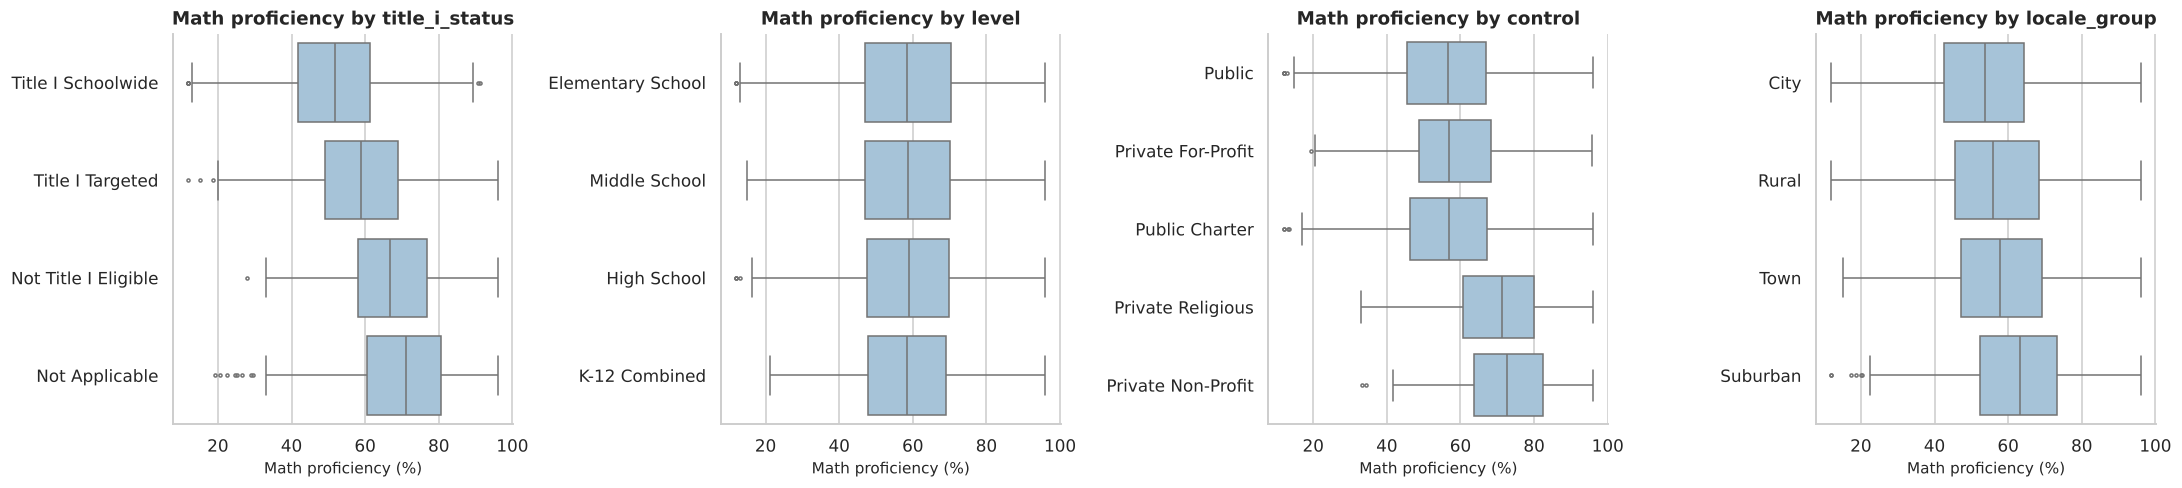

,count,mean,median,std
title_i_status,,,,
Title I Schoolwide,2180,51.7,51.8,14.3
Title I Targeted,945,58.9,58.9,14.3
Not Title I Eligible,767,67.2,66.7,13.6
Not Applicable,750,69.9,71.0,14.7


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
specs = [('title_i_status', ['Title I Schoolwide', 'Title I Targeted', 'Not Title I Eligible', 'Not Applicable']),
         ('level', ['Elementary School', 'Middle School', 'High School', 'K-12 Combined']),
         ('control', None), ('locale_group', None)]
for ax, (col, order) in zip(axes, specs):
    if order is None:
        order = k12.groupby(col)['math_proficiency_pct'].median().sort_values().index
    sns.boxplot(data=k12, y=col, x='math_proficiency_pct', order=order, ax=ax, color='#9ec5e0', fliersize=2)
    ax.set_title(f'Math proficiency by {col}'); ax.set_ylabel(''); ax.set_xlabel('Math proficiency (%)')
plt.tight_layout(); save_fig('03_math_by_category'); plt.show()

display(k12.groupby('title_i_status')['math_proficiency_pct'].agg(['count', 'mean', 'median', 'std']).round(1).sort_values('mean'))

**Reading the groups.**
- **Title I status shows the largest gaps**: Schoolwide Title I schools have the lowest average math proficiency, then Targeted, with Not Eligible and Not Applicable (private) schools highest. Title I is assigned on the basis of student poverty, so this largely restates the poverty finding in another form.
- **School level** makes very little difference once colleges are removed: elementary, middle and high schools look similar.
- **Control** and **locale** show moderate differences (suburban schools score higher than city schools). These are candidate control variables for the models.

### 3.3 Resources and opportunity: how do poverty, funding and broadband relate to *each other*?
This matters because if the predictors are strongly related to one another it becomes hard to separate their individual effects.

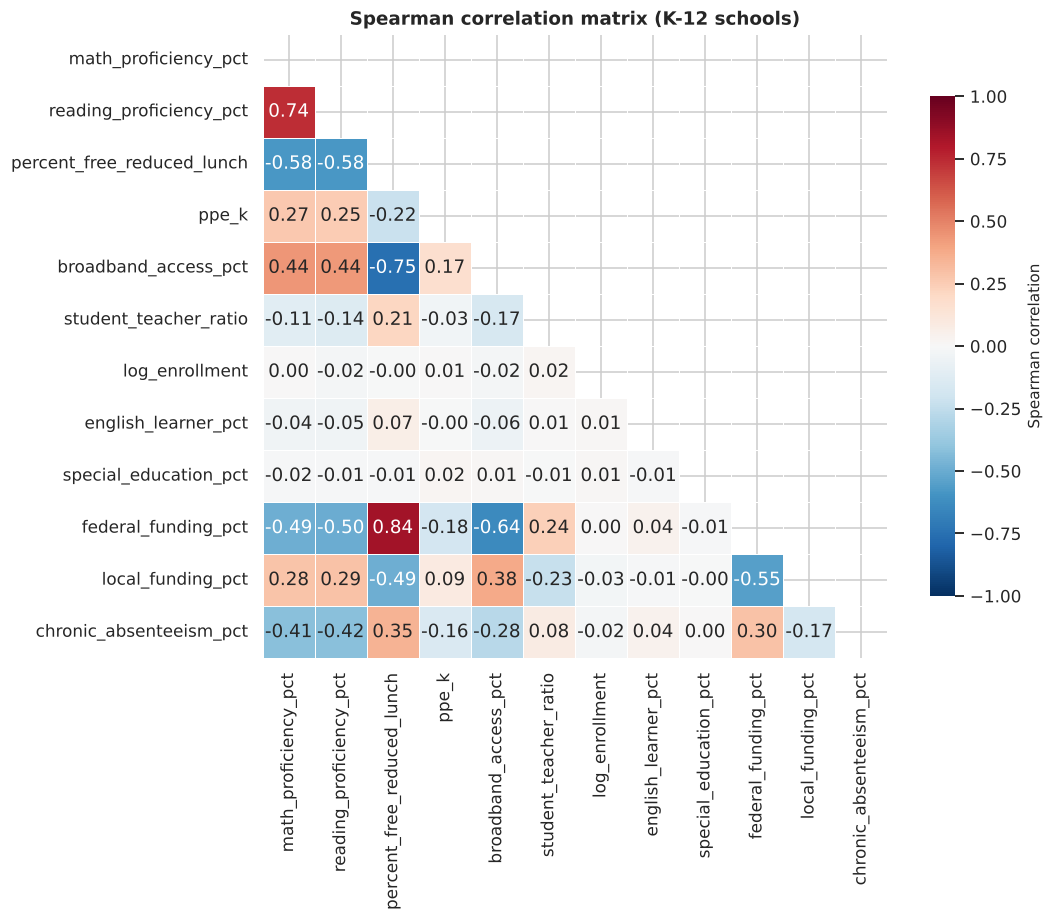

Key relationships between the predictors themselves:
  poverty vs broadband         : rho = -0.75
  poverty vs per-pupil spending: rho = -0.22
  poverty vs federal funding % : rho = 0.84


In [10]:
corr_vars = ['math_proficiency_pct', 'reading_proficiency_pct', 'percent_free_reduced_lunch', 'ppe_k', 'broadband_access_pct',
             'student_teacher_ratio', 'log_enrollment', 'english_learner_pct', 'special_education_pct',
             'federal_funding_pct', 'local_funding_pct', 'chronic_absenteeism_pct']
corr = k12[corr_vars].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10.5, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={'label': 'Spearman correlation', 'shrink': .8})
plt.title('Spearman correlation matrix (K-12 schools)')
plt.tight_layout(); save_fig('03_correlation_heatmap'); plt.show()

print('Key relationships between the predictors themselves:')
print(f"  poverty vs broadband         : rho = {corr.loc['percent_free_reduced_lunch', 'broadband_access_pct']:.2f}")
print(f"  poverty vs per-pupil spending: rho = {corr.loc['percent_free_reduced_lunch', 'ppe_k']:.2f}")
print(f"  poverty vs federal funding % : rho = {corr.loc['percent_free_reduced_lunch', 'federal_funding_pct']:.2f}")

**Reading the heatmap.** Poverty and broadband are very strongly *negatively* related: high-poverty schools tend to have lower broadband access. That is a warning sign. Broadband's raw link to math scores may be mostly poverty in disguise. Spending is only modestly related to poverty (the printed value above), so it carries more independent information than broadband does. The federal funding share rises with poverty, which is plausible because federal money is targeted at disadvantaged schools.

### 3.4 Broadband gap by locale (supporting question)

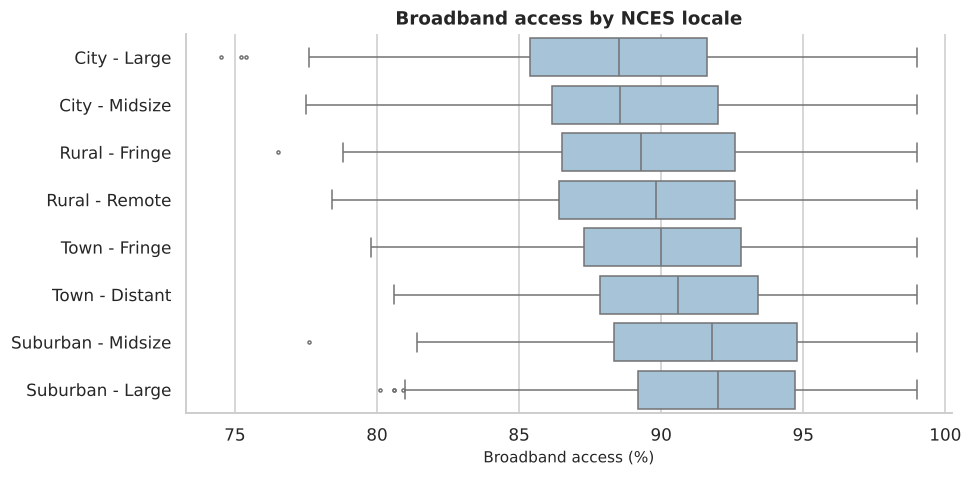

,broadband_access_pct,percent_free_reduced_lunch,math_proficiency_pct
nces_locale,,,
City - Large,88.6,55.6,53.2
City - Midsize,89.0,54.0,54.6
Rural - Fringe,89.7,48.6,57.5
Rural - Remote,89.7,49.3,57.0
Town - Fringe,90.1,43.8,58.3
Town - Distant,90.6,42.9,59.5
Suburban - Midsize,91.6,36.8,61.8
Suburban - Large,91.9,34.0,63.2


In [11]:
order = k12.groupby('nces_locale')['broadband_access_pct'].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=k12, y='nces_locale', x='broadband_access_pct', order=order, ax=ax, color='#9ec5e0', fliersize=2)
ax.set_title('Broadband access by NCES locale'); ax.set_ylabel(''); ax.set_xlabel('Broadband access (%)')
plt.tight_layout(); save_fig('03_broadband_by_locale'); plt.show()
display(k12.groupby('nces_locale')[['broadband_access_pct', 'percent_free_reduced_lunch', 'math_proficiency_pct']].mean().round(1).sort_values('broadband_access_pct'))

**Reading.** Locale differences in broadband are real but modest (a few percentage points). Surprisingly, *rural* institutions are not the lowest; the city locales have the lowest averages. In this dataset urbanicity looks like a weaker driver of the broadband gap than poverty is (high-poverty schools have noticeably lower broadband than low-poverty ones, see section 4). The formal comparison is in notebook 04.

### 3.5 STEM certification and institutional characteristics
The brief lists this as a bivariate relationship to examine. I compare certified and non-certified schools using **standardised mean differences** (Cohen's d), which puts every variable on the same scale.

,STEM certified (mean),Not certified (mean),cohens_d
variable,,,
ppe_k,16.89,16.80,0.02
percent_free_reduced_lunch,44.32,44.16,0.01
broadband_access_pct,90.38,90.39,-0.00
student_teacher_ratio,14.53,14.83,-0.09
log_enrollment,6.49,6.35,0.26
math_proficiency_pct,58.04,58.77,-0.05
reading_proficiency_pct,63.53,63.56,-0.00
chronic_absenteeism_pct,20.05,20.26,-0.04


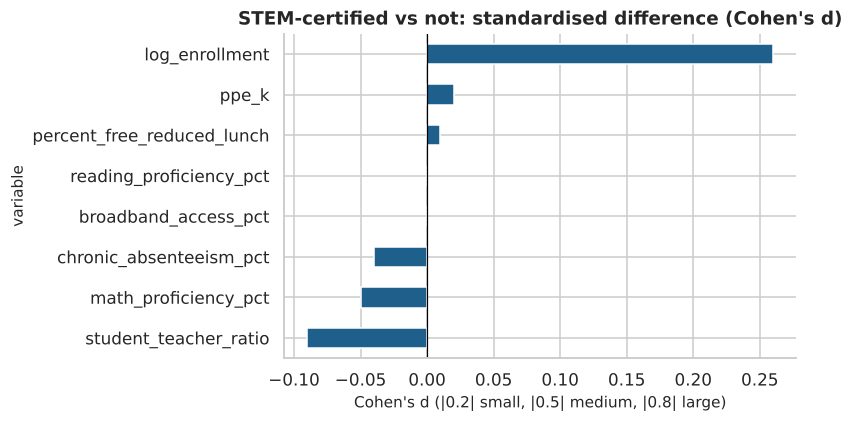

In [12]:
comp_vars = ['ppe_k', 'percent_free_reduced_lunch', 'broadband_access_pct', 'student_teacher_ratio',
             'log_enrollment', 'math_proficiency_pct', 'reading_proficiency_pct', 'chronic_absenteeism_pct']
yes, no = k12[k12['stem_certified'] == 1], k12[k12['stem_certified'] == 0]

rows = []
for c in comp_vars:
    pooled = np.sqrt(((len(yes) - 1) * yes[c].var() + (len(no) - 1) * no[c].var()) / (len(yes) + len(no) - 2))
    rows.append({'variable': c, 'STEM certified (mean)': yes[c].mean(), 'Not certified (mean)': no[c].mean(),
                 'cohens_d': (yes[c].mean() - no[c].mean()) / pooled})
stem_tbl = pd.DataFrame(rows).set_index('variable').round(2)
display(stem_tbl)

fig, ax = plt.subplots(figsize=(7.5, 4))
stem_tbl['cohens_d'].sort_values().plot.barh(ax=ax, color=PALETTE['primary'])
ax.axvline(0, color='black', lw=.8)
ax.set_title("STEM-certified vs not: standardised difference (Cohen's d)")
ax.set_xlabel("Cohen's d (|0.2| small, |0.5| medium, |0.8| large)")
plt.tight_layout(); save_fig('03_stem_cohens_d'); plt.show()

**Reading.** Almost every standardised difference is negligible (|d| below 0.1): certified and non-certified schools look alike on poverty, spending, broadband and even math scores. The one exception is **enrollment size** (d of about 0.26, a small effect): larger schools are somewhat more likely to be STEM certified. So STEM certification barely separates on the observable characteristics in this data. That is useful on its own: it suggests a STEM-certification model would struggle to predict well, and it is one reason math proficiency, which shows strong structure, is the better primary question for this capstone.

## 4. Multivariate analysis

**Central question:** does the relationship between per-pupil expenditure and math proficiency remain after considering socioeconomic conditions? Does the same hold for broadband?

The simplest honest way to look at this is to **hold poverty roughly constant**: split schools into three poverty groups (low, mid, high tertiles of free/reduced lunch) and look at the spending and broadband relationships *within* each group.

### 4.1 Spending and math proficiency, within poverty groups

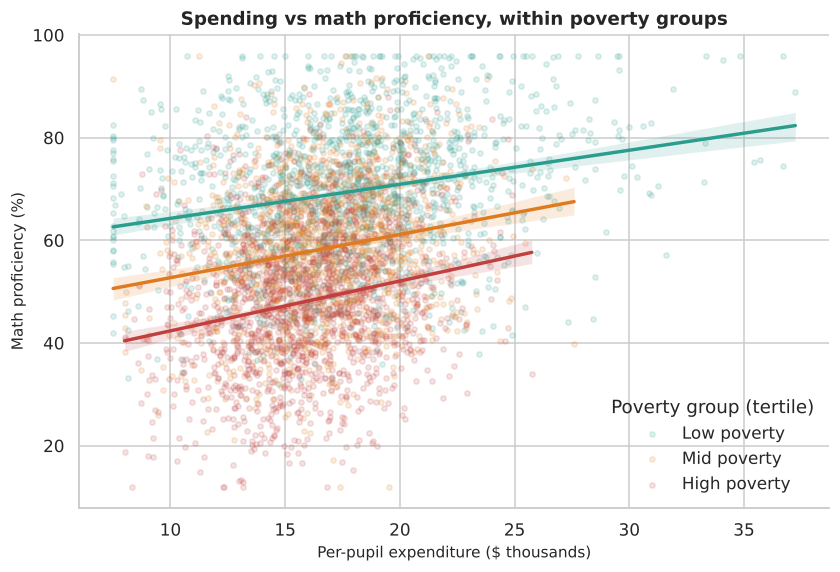

,slope (pts per $1k),r,n
Low poverty,0.66,0.23,1549.0
Mid poverty,0.84,0.19,1550.0
High poverty,0.97,0.21,1543.0


Pooled (ignoring poverty) slope: 1.25 points per $1,000


In [13]:
g = sns.lmplot(data=k12, x='ppe_k', y='math_proficiency_pct', hue='poverty_tertile',
               palette=[PALETTE['good'], PALETTE['accent'], PALETTE['bad']],
               scatter_kws={'alpha': 0.15, 's': 12}, height=5.2, aspect=1.5, legend_out=False)
g.set_axis_labels('Per-pupil expenditure ($ thousands)', 'Math proficiency (%)')
g.ax.set_title('Spending vs math proficiency, within poverty groups')
g.ax.legend(title='Poverty group (tertile)', frameon=False)
save_fig('03_spending_by_poverty'); plt.show()

slopes = {}
for grp, d in k12.groupby('poverty_tertile', observed=True):
    res = stats.linregress(d['ppe_k'], d['math_proficiency_pct'])
    slopes[grp] = (res.slope, res.rvalue, len(d))
slope_tbl = pd.DataFrame(slopes, index=['slope (pts per $1k)', 'r', 'n']).T.round(2)
display(slope_tbl)
overall = stats.linregress(k12['ppe_k'], k12['math_proficiency_pct']).slope
print(f'Pooled (ignoring poverty) slope: {overall:.2f} points per $1,000')

**Reading.** Within *every* poverty group, higher spending is still associated with higher math proficiency (the lines slope upward), so the spending relationship does not vanish when poverty is held roughly constant. The slopes inside the groups are smaller than the pooled slope: part of the raw link was poverty (lower-poverty areas tend to spend more *and* score higher), but not all of it. Note that the slope is, if anything, a little *larger* in the high-poverty group, which is worth testing formally as an interaction in notebook 04.

### 4.2 Broadband and math proficiency, within poverty groups

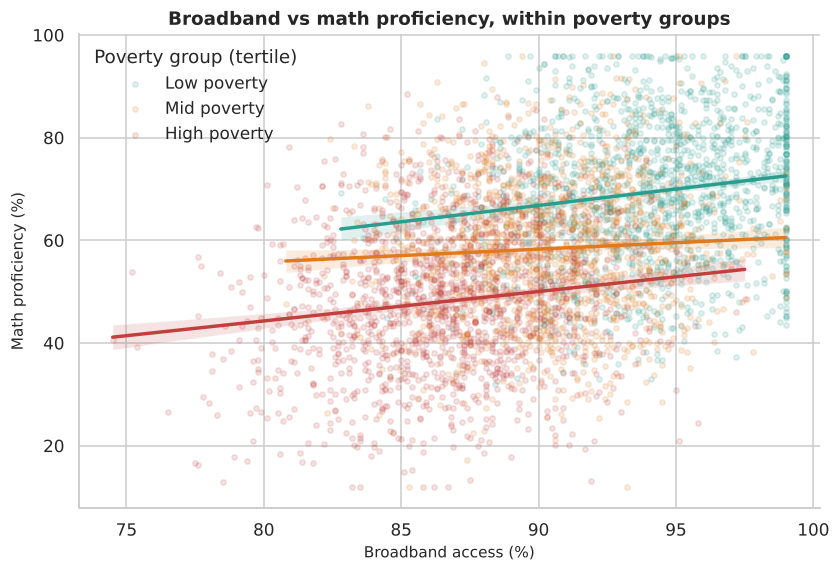

,slope (pts per 1 pct-pt),r,n
Low poverty,0.64,0.15,1549.0
Mid poverty,0.25,0.06,1550.0
High poverty,0.57,0.14,1543.0


Pooled (ignoring poverty) slope: 1.62 points per 1 percentage point of broadband


In [14]:
g = sns.lmplot(data=k12, x='broadband_access_pct', y='math_proficiency_pct', hue='poverty_tertile',
               palette=[PALETTE['good'], PALETTE['accent'], PALETTE['bad']],
               scatter_kws={'alpha': 0.15, 's': 12}, height=5.2, aspect=1.5, legend_out=False)
g.set_axis_labels('Broadband access (%)', 'Math proficiency (%)')
g.ax.set_title('Broadband vs math proficiency, within poverty groups')
g.ax.legend(title='Poverty group (tertile)', frameon=False)
save_fig('03_broadband_by_poverty'); plt.show()

slopes_bb = {}
for grp, d in k12.groupby('poverty_tertile', observed=True):
    res = stats.linregress(d['broadband_access_pct'], d['math_proficiency_pct'])
    slopes_bb[grp] = (res.slope, res.rvalue, len(d))
display(pd.DataFrame(slopes_bb, index=['slope (pts per 1 pct-pt)', 'r', 'n']).T.round(2))
overall_bb = stats.linregress(k12['broadband_access_pct'], k12['math_proficiency_pct']).slope
print(f'Pooled (ignoring poverty) slope: {overall_bb:.2f} points per 1 percentage point of broadband')

**Reading.** The *pooled* broadband relationship is steep, but the slope **drops sharply inside every poverty group** (compare the pooled slope printed above with the three group slopes, and the correlations *r*, which are small within groups). Much of broadband's apparent link to math scores came from the fact that broadband and poverty move together. This pattern, where an apparent effect shrinks after accounting for a third variable, is called **confounding**, and it is the most important lesson in this dataset.

One honest caveat: three poverty tertiles are a *crude* control, because poverty still varies a lot *within* each tertile and broadband is strongly linked to that remaining variation. The regression in notebook 04, which uses poverty as a continuous covariate, is the fair test of how much broadband adds once poverty is accounted for.

### 4.3 A grid view: average math proficiency by spending quartile × poverty group

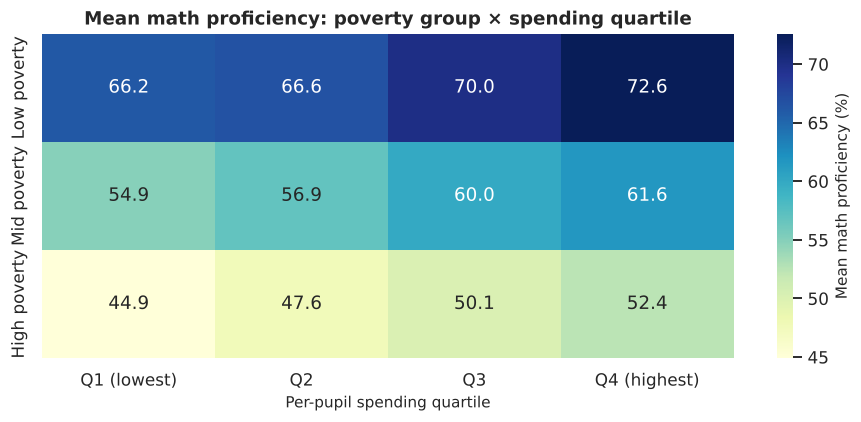

spending_quartile,Q1 (lowest),Q2,Q3,Q4 (highest)
poverty_tertile,,,,
Low poverty,326,297,357,569
Mid poverty,334,443,425,348
High poverty,501,421,377,244


Within each poverty group, the gap between top and bottom spending quartile:
poverty_tertile
Low poverty     6.4
Mid poverty     6.6
High poverty    7.5

Poverty gap (high vs low poverty) within the lowest spending quartile : 21.3 points
Poverty gap (high vs low poverty) within the highest spending quartile: 20.2 points


In [15]:
k12['spending_quartile'] = pd.qcut(k12['ppe_k'], 4, labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
grid = k12.pivot_table(index='poverty_tertile', columns='spending_quartile', values='math_proficiency_pct', aggfunc='mean', observed=True)
counts = k12.pivot_table(index='poverty_tertile', columns='spending_quartile', values='math_proficiency_pct', aggfunc='size', observed=True)

plt.figure(figsize=(8.5, 4))
sns.heatmap(grid, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': 'Mean math proficiency (%)'})
plt.title('Mean math proficiency: poverty group × spending quartile')
plt.xlabel('Per-pupil spending quartile'); plt.ylabel('')
plt.tight_layout(); save_fig('03_poverty_spending_grid'); plt.show()
display(counts)
print('Within each poverty group, the gap between top and bottom spending quartile:')
print((grid['Q4 (highest)'] - grid['Q1 (lowest)']).round(1).to_string())
print(f"\nPoverty gap (high vs low poverty) within the lowest spending quartile : {grid.loc['Low poverty', 'Q1 (lowest)'] - grid.loc['High poverty', 'Q1 (lowest)']:.1f} points")
print(f"Poverty gap (high vs low poverty) within the highest spending quartile: {grid.loc['Low poverty', 'Q4 (highest)'] - grid.loc['High poverty', 'Q4 (highest)']:.1f} points")

**Reading the grid.** Reading *down* a column shows the poverty penalty at a fixed spending level; reading *across* a row shows the spending bonus at a fixed poverty level. The poverty effect (down columns) is much larger than the spending effect (across rows), and extra spending does not erase the gap between low- and high-poverty schools. Every cell has a healthy number of schools (see the counts table), so no cell is driven by a handful of observations.

### 4.4 Do the patterns hold across school levels?

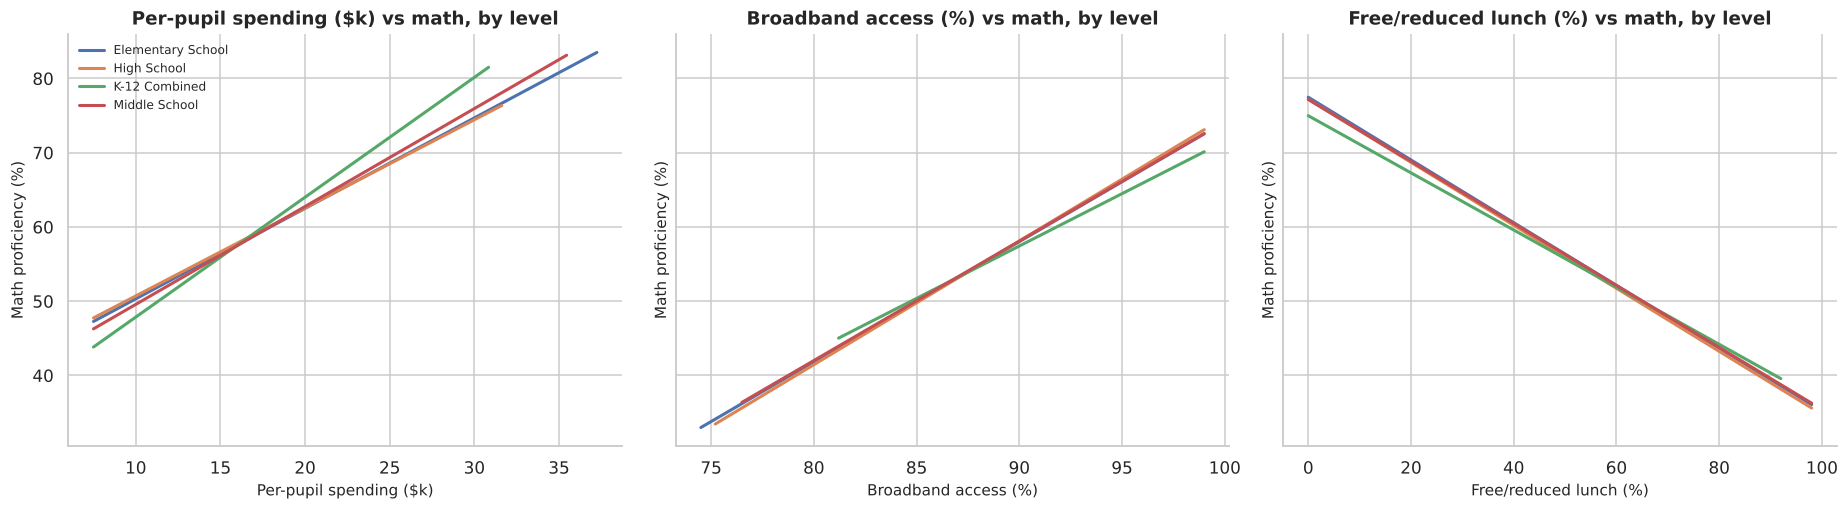

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, (col, label) in zip(axes, [('ppe_k', 'Per-pupil spending ($k)'), ('broadband_access_pct', 'Broadband access (%)'), ('percent_free_reduced_lunch', 'Free/reduced lunch (%)')]):
    for lvl, d in k12.groupby('level'):
        sns.regplot(data=d, x=col, y='math_proficiency_pct', scatter=False, ax=ax, ci=None, label=lvl, line_kws={'lw': 2})
    ax.set_xlabel(label); ax.set_ylabel('Math proficiency (%)'); ax.set_title(f'{label} vs math, by level')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save_fig('03_relationships_by_level'); plt.show()

**Reading.** The fitted lines for the four school levels are close to one another for all three predictors (K-12 Combined has a somewhat steeper spending line but contains only about 200 schools, so it is the noisiest). The relationships are broadly **consistent across levels**, which supports pooling elementary, middle, high and K-12 schools in one model with level as a control variable. Notebook 04 checks this formally by fitting each level separately.

### 4.5 Absenteeism as a pathway (context only)

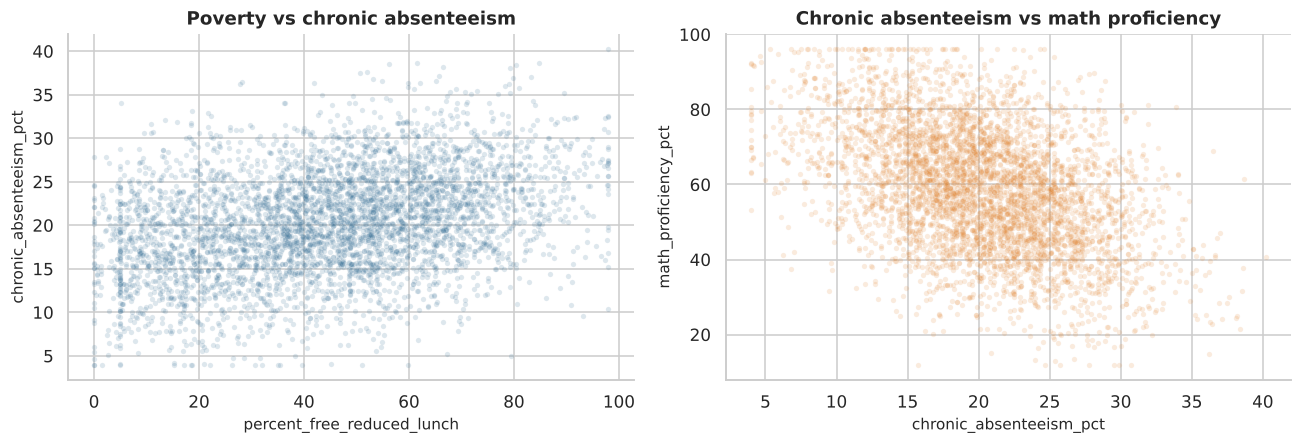

poverty ~ absenteeism r = 0.35
absenteeism ~ math    r = -0.43


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.scatterplot(data=k12, x='percent_free_reduced_lunch', y='chronic_absenteeism_pct', alpha=.15, s=12, ax=ax[0], color=PALETTE['primary'])
ax[0].set_title('Poverty vs chronic absenteeism')
sns.scatterplot(data=k12, x='chronic_absenteeism_pct', y='math_proficiency_pct', alpha=.15, s=12, ax=ax[1], color=PALETTE['accent'])
ax[1].set_title('Chronic absenteeism vs math proficiency')
plt.tight_layout(); save_fig('03_absenteeism_pathway'); plt.show()
print(f"poverty ~ absenteeism r = {k12['percent_free_reduced_lunch'].corr(k12['chronic_absenteeism_pct']):.2f}")
print(f"absenteeism ~ math    r = {k12['chronic_absenteeism_pct'].corr(k12['math_proficiency_pct']):.2f}")

Absenteeism is tied to both poverty and achievement. It plausibly sits *between* them (poverty → absenteeism → lower scores), so it is an outcome or pathway, not a school resource. Including it as a predictor would blur what the model learns about resources, so I leave it out of the models.

## 5. EDA takeaways

| # | Observation | Implication for the next notebooks |
|---|---|---|
| 1 | Math proficiency is roughly symmetric with no missing values | Linear regression is appropriate; no target transformation needed |
| 2 | Poverty (free/reduced lunch) has the strongest raw link to math scores | It must be controlled for in every model |
| 3 | Spending shows a positive link that **persists within poverty groups** (but smaller than the pooled link) | Formal test: is the spending coefficient still significant after controlling for poverty? |
| 4 | Broadband shows a strong raw link that **shrinks sharply within poverty groups** | Formal test with poverty as a continuous covariate; expect a much smaller adjusted effect |
| 5 | Poverty and broadband are strongly correlated | Check multicollinearity (VIF); be careful interpreting separate effects |
| 6 | Title I gaps mirror the poverty gradient | Title I mostly restates poverty; compare, but do not over-interpret |
| 7 | STEM certification barely differs on observed characteristics (enrollment size is the one small exception) | STEM prediction would likely be weak, so regression on math proficiency is the better ML task |
| 8 | Relationships are consistent across school levels | Pool the levels; include `level` as a control |
| 9 | Absenteeism is a pathway, not a resource | Exclude from predictors |

**Next → `04_statistical_analysis.ipynb`:** turn these visual impressions into formal estimates with confidence intervals and tests.